# 05 · Ngưỡng và phân tích lỗi — Word Final v7.1
Đối chiếu Bảng 5.6, 5.12–5.15, Phụ lục D/E và PPT slide 23/32/33. Mỗi phần có bảng và kết quả tính trực tiếp. Không huấn luyện hoặc chọn lại ngưỡng theo test. A/B một lượt; mỗi C đủ ba seed.

In [1]:
from pathlib import Path
import importlib.util, json
import numpy as np
import pandas as pd
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "experiments/threshold_error_20261110/analysis.py").exists())
folder = root / "experiments/threshold_error_20261110"
spec = importlib.util.spec_from_file_location("threshold_analysis", folder / "analysis.py")
a = importlib.util.module_from_spec(spec); spec.loader.exec_module(a)
a.ensure_inputs("validation")
lock = a.read(folder / "validation_lock.json")
receipt = a.read(folder / "results/verification.json")
assert receipt["validation_lock_sha256"] == a.sha(folder / "validation_lock.json")
print("11 bộ kết quả; ba seed cho mỗi C, một lượt cho A và B.")
import sys
if str(root) not in sys.path:sys.path.insert(0,str(root))
import matplotlib.pyplot as plt
from src import report_figures as charts

11 bộ kết quả; ba seed cho mỗi C, một lượt cho A và B.


## 1. Kiểm toán lại validation
Điểm phải đúng ID và thứ tự 28 nhãn. Ngưỡng tính lại cần khớp bản đã khóa; nếu khác, dừng và không thay ngưỡng theo test.

In [2]:
vf = pd.read_parquet(root / lock["validation_data"])
vy = a.targets(vf)
audits=[]
for run in lock["checkpoints"]:
    assert a.sha(root / run["val_scores"]) == run["validation_scores_sha256"]
    vs = a.load_scores(root / run["val_scores"], vf, lock["label_names"])
    thresholds, global_t, _ = a.select(vs, vy)
    different = int((np.abs(thresholds - np.array(run["thresholds"])) > 1e-6).sum())
    assert different == 0 and abs(global_t - run["global_threshold"]) < 1e-6
    audits.append({"model": run["model"], "seed": run["seed"], "khac_nguong": different, "nguong_chung": global_t})
display(pd.DataFrame(audits))

,model,seed,khac_nguong,nguong_chung
0,C1 BERT,42.0,0,0.20
1,C1 BERT,123.0,0,0.20
2,C1 BERT,2026.0,0,0.25
3,C2 RoBERTa,42.0,0,0.40
4,C2 RoBERTa,123.0,0,0.25
5,C2 RoBERTa,2026.0,0,0.25
6,C3 DistilBERT,42.0,0,0.20
7,C3 DistilBERT,123.0,0,0.20
8,C3 DistilBERT,2026.0,0,0.10
9,A TF-IDF balanced,42.0,0,0.55


## 2. Tái hiện đủ ba chế độ trên test
Đây là đánh giá các lựa chọn đã khóa. Không dùng kết quả để chọn lại chế độ, epoch hay mô hình.

,model,mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,hamming_mean
0,C1 BERT,fixed,3,0.469636,0.005473,0.570629,0.033356
1,C1 BERT,global,3,0.479374,0.003752,0.566296,0.040170
2,C1 BERT,tuned,3,0.493794,0.007451,0.571725,0.040450
3,C2 RoBERTa,fixed,3,0.476459,0.007916,0.574146,0.032523
4,C2 RoBERTa,global,3,0.498482,0.012112,0.580268,0.037164
5,C2 RoBERTa,tuned,3,0.510117,0.007619,0.590873,0.037713
6,C3 DistilBERT,fixed,3,0.472875,0.003889,0.570709,0.032876
7,C3 DistilBERT,global,3,0.488286,0.005534,0.562286,0.043587
8,C3 DistilBERT,tuned,3,0.497209,0.002687,0.577897,0.038919
9,A TF-IDF balanced,fixed,1,0.444052,NaN,0.502364,0.054720


Khớp 33/33 bộ metric từ điểm dự đoán thật.


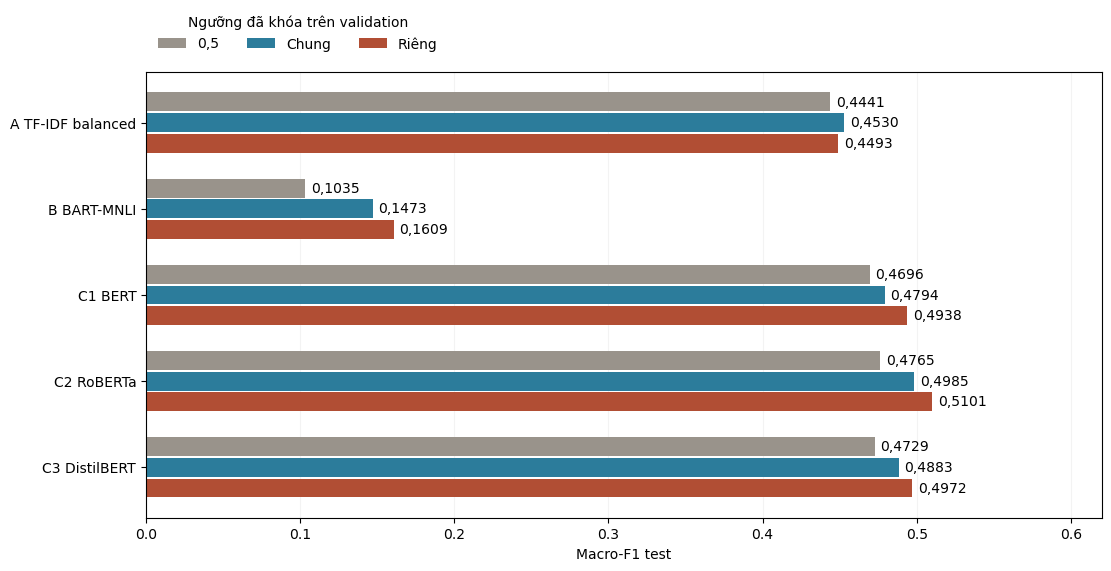

A là phản ví dụ: ngưỡng chung có Macro-F1 cao hơn ngưỡng riêng. Không chọn lại bằng test.


In [3]:
a.ensure_inputs("test")
tf = pd.read_parquet(a.OLD / "main_results/data/raw/test-00000-of-00001.parquet")
ty = a.targets(tf)
saved = pd.read_csv(folder / "results/modes_per_checkpoint.csv")
checks = 0
for run in lock["checkpoints"]:
    ts = a.load_scores(root / run["test_scores"], tf, lock["label_names"])
    for mode, thresholds in {"fixed": .5, "global": run["global_threshold"], "tuned": np.array(run["thresholds"])}.items():
        actual = a.metrics(ty, ts >= thresholds)
        rows = saved[(saved.model == run["model"]) & (saved["mode"] == mode)]
        rows = rows[rows.seed.isna()] if run["seed"] is None else rows[rows.seed == run["seed"]]
        assert len(rows) == 1
        for key, value in actual.items():
            assert abs(value - rows.iloc[0][key]) < 1e-12, (run["model"], mode, key)
        checks += 1
summary = pd.read_csv(folder / "results/modes_mean_std.csv")
assert checks == 33
display(summary[["model","mode","n_runs","macro_f1_mean","macro_f1_std","micro_f1_mean","hamming_mean"]])
print("Khớp 33/33 bộ metric từ điểm dự đoán thật.")
fig=charts.threshold_modes(summary);plt.show();plt.close(fig)
print("A là phản ví dụ: ngưỡng chung có Macro-F1 cao hơn ngưỡng riêng. Không chọn lại bằng test.")

A đạt Macro-F1 ngưỡng chung cao hơn ngưỡng riêng. Ba C có Macro-F1 ngưỡng riêng cao hơn nhưng Hamming Loss và exact match có thể xấu đi. Std là độ lệch chuẩn mẫu giữa ba seed, không phải khoảng tin cậy.

## 3. Năm loại câu loại trừ nhau và giao ba tập lỗi cũ

model,C1 BERT,C2 RoBERTa,C3 DistilBERT
category,,,
doan_sai_nhan,1763,1548,1607
doan_thua,236,165,247
dung_hoan_toan,2540,2526,2476
dung_mot_phan,507,497,493
khong_doan_gi,381,691,604


,model,g1,g2,g3,g1_and_g2,g1_and_g3,g2_and_g3,all_three,union
6,C1 BERT,507,71,1813,19,50,35,1,2288
15,C2 RoBERTa,497,69,1582,21,34,27,0,2066
24,C3 DistilBERT,493,68,1650,17,43,24,0,2127


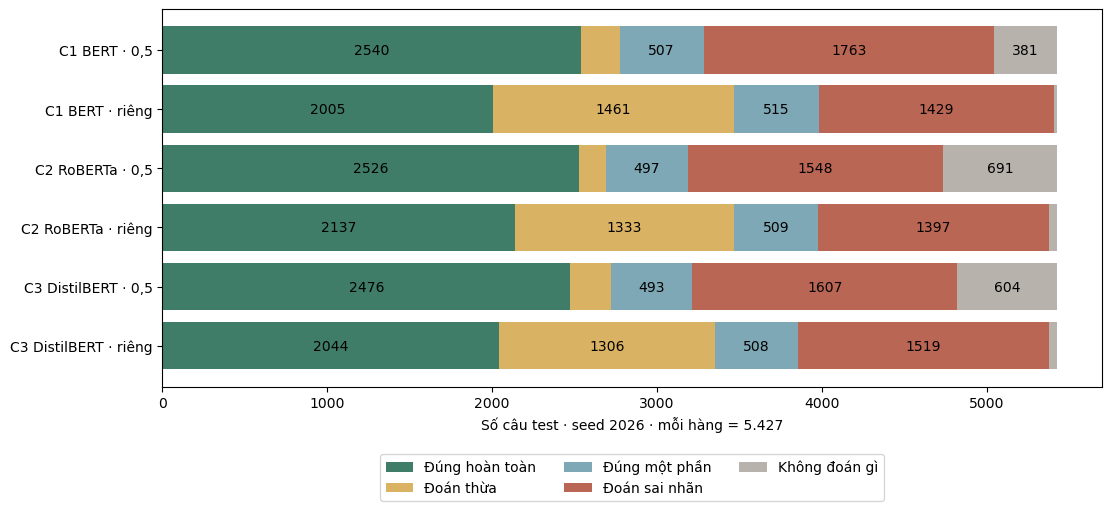

In [4]:
tax = pd.read_csv(folder / "results/error_taxonomy.csv")
assert (tax.groupby(["model","seed","mode"], dropna=False).n.sum() == 5427).all()
overlap = pd.read_csv(folder / "results/error_overlap.csv")
union = overlap.g1 + overlap.g2 + overlap.g3 - overlap.g1_and_g2 - overlap.g1_and_g3 - overlap.g2_and_g3 + overlap.all_three
assert (union == overlap["union"]).all()
assert (overlap[[f"only_mask_{i}" for i in range(1,8)]].sum(axis=1) == union).all()
display(tax[(tax.seed==2026)&(tax["mode"]=="fixed")].pivot(index="category",columns="model",values="n"))
display(overlap[(overlap.seed==2026)&(overlap["mode"]=="fixed")][["model","g1","g2","g3","g1_and_g2","g1_and_g3","g2_and_g3","all_three","union"]])
fig=charts.exclusive_errors(tax);plt.show();plt.close(fig)

## 4. Toàn bộ ngưỡng, support và lỗi gần ngưỡng

C1 BERT — đủ 28 ngưỡng theo ba seed:


seed,42.0,123.0,2026.0
label,,,
admiration,0.50,0.35,0.45
amusement,0.50,0.40,0.50
anger,0.40,0.60,0.35
annoyance,0.15,0.15,0.10
approval,0.20,0.15,0.35
caring,0.30,0.65,0.30
confusion,0.25,0.40,0.45
curiosity,0.30,0.15,0.15
desire,0.45,0.40,0.25


C2 RoBERTa — đủ 28 ngưỡng theo ba seed:


seed,42.0,123.0,2026.0
label,,,
admiration,0.40,0.35,0.45
amusement,0.60,0.30,0.45
anger,0.30,0.40,0.35
annoyance,0.20,0.25,0.20
approval,0.45,0.30,0.25
caring,0.55,0.15,0.30
confusion,0.50,0.25,0.25
curiosity,0.15,0.10,0.35
desire,0.40,0.25,0.45


C3 DistilBERT — đủ 28 ngưỡng theo ba seed:


seed,42.0,123.0,2026.0
label,,,
admiration,0.50,0.55,0.50
amusement,0.20,0.15,0.30
anger,0.30,0.35,0.75
annoyance,0.25,0.30,0.10
approval,0.20,0.30,0.20
caring,0.20,0.30,0.45
confusion,0.35,0.50,0.50
curiosity,0.15,0.15,0.05
desire,0.40,0.40,0.30


model,A TF-IDF balanced,B BART-MNLI
label,,
admiration,0.55,0.95
amusement,0.60,0.95
anger,0.60,0.95
annoyance,0.45,0.95
approval,0.60,0.95
caring,0.65,0.95
confusion,0.65,0.95
curiosity,0.70,0.95
desire,0.80,0.95


low  high
model             seed             
A TF-IDF balanced 42.0      0     0
B BART-MNLI       NaN       1    26
C1 BERT           42.0      3     0
                  123.0     0     0
                  2026.0    4     0
C2 RoBERTa        42.0      1     0
                  123.0     1     0
                  2026.0    2     0
C3 DistilBERT     42.0      1     0
                  123.0     0     0
                  2026.0    1     0

B có 26/28 ngưỡng riêng ở 0,95. Chỉ tối ưu trong lưới đã khóa, chưa chứng minh tối ưu toàn [0,1]. Không mở lưới sau khi xem test.


,model,type,n,share_ratio_ge_0_8,share_margin_le_0_1
16,C1 BERT,FN,2137,0.059897,NaN
17,C1 BERT,FP,4201,NaN,0.282076
34,C2 RoBERTa,FN,2145,0.098834,NaN
35,C2 RoBERTa,FP,3558,NaN,0.276560
52,C3 DistilBERT,FN,2275,0.073407,NaN
53,C3 DistilBERT,FP,3838,NaN,0.264721


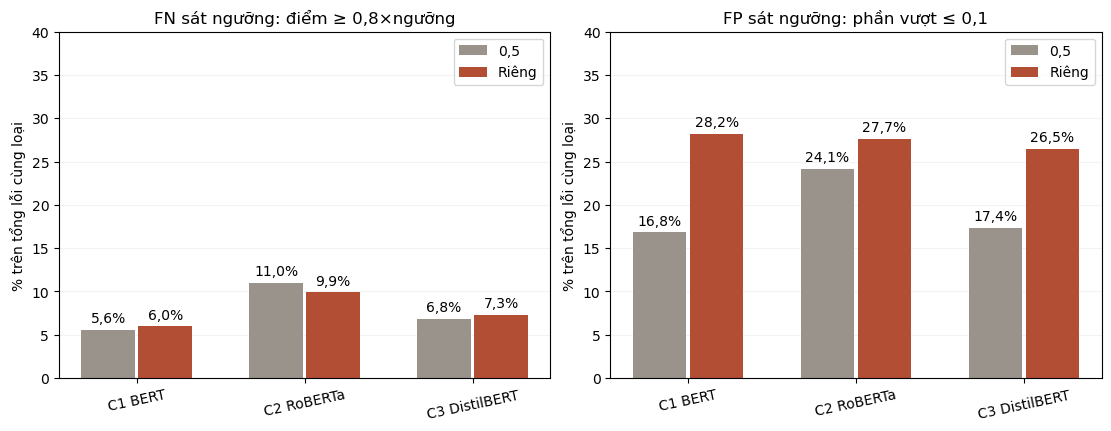

In [5]:
thresholds=pd.read_csv(folder/'results/thresholds_28.csv')
assert len(thresholds)==11*28
for model in ['C1 BERT','C2 RoBERTa','C3 DistilBERT']:
    table=thresholds[thresholds.model==model]
    print(model,'— đủ 28 ngưỡng theo ba seed:')
    display(table.pivot(index='label',columns='seed',values='threshold_label'))
single=thresholds[thresholds.model.isin(['A TF-IDF balanced','B BART-MNLI'])]
display(single.pivot(index='label',columns='model',values='threshold_label'))
boundary=thresholds.assign(low=thresholds.threshold_label.eq(.05),high=thresholds.threshold_label.eq(.95)).groupby(['model','seed'],dropna=False)[['low','high']].sum()
display(boundary)
print('B có 26/28 ngưỡng riêng ở 0,95. Chỉ tối ưu trong lưới đã khóa, chưa chứng minh tối ưu toàn [0,1]. Không mở lưới sau khi xem test.')
near=pd.read_csv(folder/'results/near_miss.csv')
display(near[(near.seed==2026)&(near['mode']=='tuned')][['model','type','n','share_ratio_ge_0_8','share_margin_le_0_1']])
fig=charts.near_miss(near);plt.show();plt.close(fig)

Near-miss chỉ mô tả vị trí lỗi so với ngưỡng đã khóa. FN sát ngưỡng: điểm ≥0,8×ngưỡng; FP sát ngưỡng: phần vượt ≤0,1. Không dùng bảng này để đổi ngưỡng theo test.

## 5. Kiểm số ví dụ caring/optimism và bảng epoch

In [6]:
display(pd.read_csv(folder / "results/caring_optimism_verified.csv"))
sweep = pd.read_csv(a.OLD / "sweep_log.csv")
assert len(sweep) == 72
chosen = sweep.sort_values(["val_macro_f1","epoch"],ascending=[False,True]).groupby(["model","seed"],sort=False).head(1)
display(chosen[["model","seed","epoch","val_macro_f1","val_bce"]].sort_values(["model","seed"]))
print("BCE validation thấp nhất:")
display(sweep.sort_values(["val_bce","epoch"]).groupby(["model","seed"]).head(1)[["model","seed","epoch","val_bce"]])

,model,seed,mode,id,caring,optimism,truth,prediction
0,C1 BERT,2026,fixed,eeq65gb,0.902438,0.260389,caring|optimism,caring
1,C1 BERT,2026,tuned,eeq65gb,0.902438,0.260389,caring|optimism,caring
2,C2 RoBERTa,2026,fixed,eeq65gb,0.910067,0.077100,caring|optimism,caring
3,C2 RoBERTa,2026,tuned,eeq65gb,0.910067,0.077100,caring|optimism,caring
4,C3 DistilBERT,2026,fixed,eeq65gb,0.862930,0.369429,caring|optimism,caring
5,C3 DistilBERT,2026,tuned,eeq65gb,0.862930,0.369429,caring|optimism,caring|optimism


,model,seed,epoch,val_macro_f1,val_bce
6,BERT,42,7,0.455969,0.106145
13,BERT,123,6,0.461938,0.101499
22,BERT,2026,7,0.464495,0.105355
54,DistilBERT,42,7,0.468009,0.105085
63,DistilBERT,123,8,0.468118,0.106701
71,DistilBERT,2026,8,0.473971,0.105625
30,RoBERTa,42,7,0.484181,0.094248
39,RoBERTa,123,8,0.466438,0.097775
44,RoBERTa,2026,5,0.489797,0.088151


BCE validation thấp nhất:


,model,seed,epoch,val_bce
26,RoBERTa,42,3,0.083334
42,RoBERTa,2026,3,0.084064
58,DistilBERT,123,3,0.084258
34,RoBERTa,123,3,0.084559
50,DistilBERT,42,3,0.084808
66,DistilBERT,2026,3,0.084857
18,BERT,2026,3,0.085459
2,BERT,42,3,0.085709
10,BERT,123,3,0.085765


## 6. Phiếu độc lập cho hai người gán nhãn
Chưa có hai phiếu thật nên không báo cáo đồng thuận hoặc kết luận nguyên nhân. Các giả thuyết cần được kiểm tra bằng ví dụ và ablation.

In [7]:
for name in ["Duy","Huy"]:
    form = pd.read_csv(folder / f"results/phieu_doc_lap_{name}.csv")
    print(name, "số mục:", len(form), "đã điền:", int(form.nhan_thu_cong.notna().sum()))
print("Các bảng đã tái hiện. Không có bước huấn luyện mô hình.")
pairs=pd.read_csv(folder/'results/pair_counts_long.csv')
display(pairs[(pairs.seed==2026)&(((pairs.fn_label=='relief')&(pairs.fp_label=='admiration'))|((pairs.fn_label=='neutral')&(pairs.fp_label=='approval')))])
print('relief→admiration chỉ một câu/mô hình đại diện, là ví dụ đơn lẻ. Neutral→approval có đủ câu lấy tối đa 20. Chưa có hai phiếu thật nên chưa chốt nguyên nhân.')

Duy số mục: 145 đã điền: 0
Huy số mục: 145 đã điền: 0
Các bảng đã tái hiện. Không có bước huấn luyện mô hình.


,model,seed,fn_label,fp_label,n
1161,C1 BERT,2026.0,relief,admiration,1
1210,C1 BERT,2026.0,neutral,approval,42
2348,C2 RoBERTa,2026.0,relief,admiration,1
2394,C2 RoBERTa,2026.0,neutral,approval,43
3536,C3 DistilBERT,2026.0,relief,admiration,1
3581,C3 DistilBERT,2026.0,neutral,approval,67


relief→admiration chỉ một câu/mô hình đại diện, là ví dụ đơn lẻ. Neutral→approval có đủ câu lấy tối đa 20. Chưa có hai phiếu thật nên chưa chốt nguyên nhân.


## 7. F1 của năm nhãn hiếm — Word Bảng 5.7, PPT slide 28
Mỗi nhãn được tính mean và std mẫu trên đủ ba seed. Đồ thị dùng đúng thứ tự grief/pride/relief/nervousness/embarrassment; không bỏ nhãn bị giảm F1.

,model,label,mode,mean,std
0,C1 BERT,embarrassment,fixed,0.494525,0.012629
1,C1 BERT,embarrassment,tuned,0.479353,0.036536
2,C1 BERT,grief,fixed,0.000000,0.000000
3,C1 BERT,grief,tuned,0.114286,0.103016
4,C1 BERT,nervousness,fixed,0.305964,0.024780
5,C1 BERT,nervousness,tuned,0.305263,0.034557
6,C1 BERT,pride,fixed,0.183465,0.057299
7,C1 BERT,pride,tuned,0.457986,0.078811
8,C1 BERT,relief,fixed,0.000000,0.000000
9,C1 BERT,relief,tuned,0.265416,0.007875


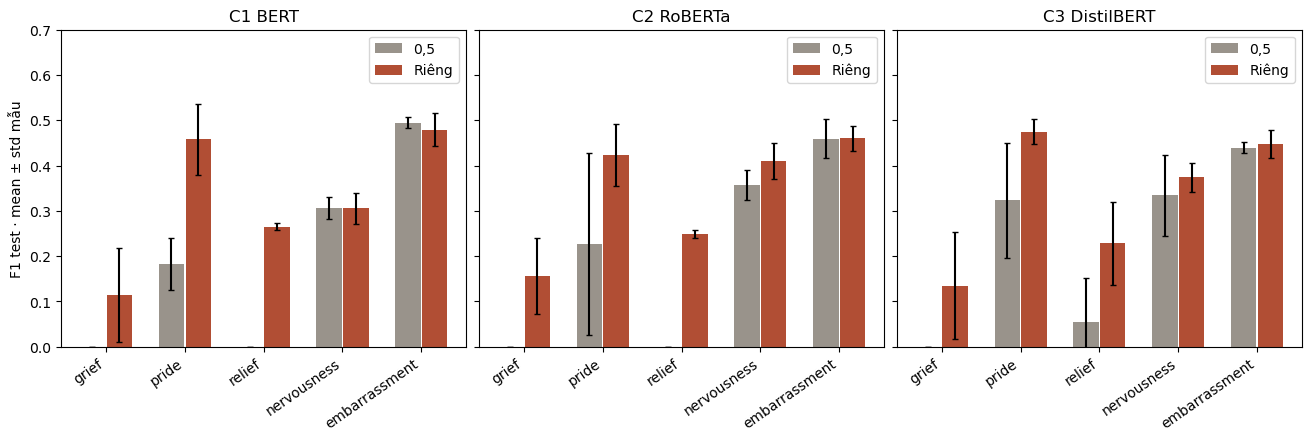

grief chỉ có 6 mẫu test. F1 nhãn hiếm có thể dao động mạnh; giữ cả nhãn bị giảm.


In [8]:
per_label=pd.read_csv(folder/'results/label_tpfpfn.csv')
rare=['grief','pride','relief','nervousness','embarrassment']
data=per_label[per_label.model.str.startswith('C') & per_label.label.isin(rare) & per_label['mode'].isin(['fixed','tuned'])]
rare_c=data.groupby(['model','label','mode']).f1.agg(['mean','std']).reset_index()
display(rare_c)
fig,axes=plt.subplots(1,3,figsize=(13,4.3),layout='constrained',sharey=True)
for ax,model in zip(axes,['C1 BERT','C2 RoBERTa','C3 DistilBERT']):
    for i,mode in enumerate(['fixed','tuned']):
        rows=rare_c[(rare_c.model==model)&(rare_c['mode']==mode)].set_index('label').loc[rare]
        ax.bar(np.arange(5)+(i-.5)*.34,rows['mean'],yerr=rows['std'],width=.32,capsize=2,label='0,5' if mode=='fixed' else 'Riêng',color='#99938B' if mode=='fixed' else '#B14E34')
    ax.set_xticks(np.arange(5),rare,rotation=35,ha='right');ax.set_title(model);ax.set_ylim(0,.7);ax.legend()
axes[0].set_ylabel('F1 test · mean ± std mẫu');plt.show();plt.close(fig)
print('grief chỉ có 6 mẫu test. F1 nhãn hiếm có thể dao động mạnh; giữ cả nhãn bị giảm.')

## 8. Ma trận FN→FP từ điểm thật — Word Phụ lục C / PPT slide 19
Tính ở **seed 2026, ngưỡng 0,5** để khớp slide. Hàng là nhãn bị bỏ sót, cột là nhãn thêm sai trong cùng câu. Một câu có thể đóng góp nhiều cặp; đây không phải confusion matrix đơn nhãn và không chứng minh nguyên nhân.

,neutral,approval,annoyance,disapproval,admiration
C1 BERT,,,,,
neutral,0,89,66,75,46
approval,81,0,5,8,17
annoyance,66,14,0,21,4
disapproval,55,4,11,0,5
admiration,21,19,3,2,0


,neutral,approval,annoyance,disapproval,admiration
C2 RoBERTa,,,,,
neutral,0,71,41,71,68
approval,53,0,3,9,23
annoyance,43,8,0,23,4
disapproval,42,3,6,0,6
admiration,16,11,1,1,0


,neutral,approval,annoyance,disapproval,admiration
C3 DistilBERT,,,,,
neutral,0,80,52,59,53
approval,80,0,3,14,18
annoyance,71,9,0,17,5
disapproval,66,1,12,0,5
admiration,24,16,0,4,0


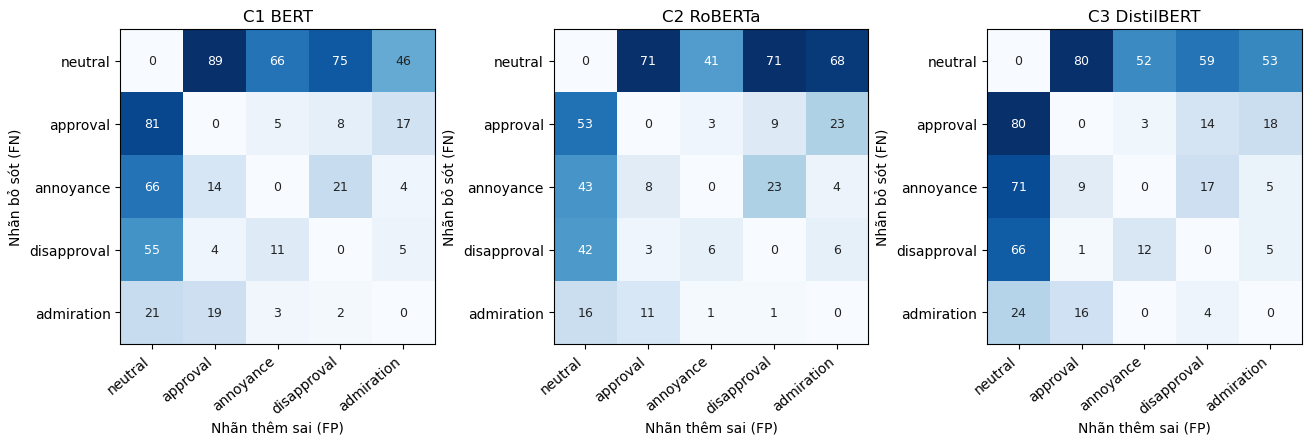

PASS: BERT neutral→approval = 89 ở ngưỡng 0,5, khớp slide 19. Bảng 5.15 dùng ngưỡng riêng, không trộn hai chế độ.


In [9]:
focus=['neutral','approval','annoyance','disapproval','admiration']
indices=[lock['label_names'].index(label) for label in focus]
fig,axes=plt.subplots(1,3,figsize=(13,4.3),layout='constrained')
for ax,model in zip(axes,['C1 BERT','C2 RoBERTa','C3 DistilBERT']):
    run=next(r for r in lock['checkpoints'] if r['model']==model and r['seed']==2026)
    points=a.load_scores(root/run['test_scores'],tf,lock['label_names']);prediction=points>=.5
    fn=ty & ~prediction;fp=~ty & prediction
    matrix=fn.astype(np.int64).T@fp.astype(np.int64);np.fill_diagonal(matrix,0)
    small=matrix[np.ix_(indices,indices)]
    display(pd.DataFrame(small,index=focus,columns=focus).rename_axis(model))
    ax.imshow(small,cmap='Blues',vmin=0,vmax=max(1,small.max()))
    for i in range(5):
        for j in range(5):ax.text(j,i,str(small[i,j]),ha='center',va='center',color='white' if small[i,j]>.55*small.max() else '#222222',fontsize=9)
    ax.set_xticks(range(5),focus,rotation=40,ha='right');ax.set_yticks(range(5),focus);ax.set_title(model)
    ax.set_xlabel('Nhãn thêm sai (FP)');ax.set_ylabel('Nhãn bỏ sót (FN)')
    if model=='C1 BERT':assert int(small[0,1])==89
plt.show();plt.close(fig)
print('PASS: BERT neutral→approval = 89 ở ngưỡng 0,5, khớp slide 19. Bảng 5.15 dùng ngưỡng riêng, không trộn hai chế độ.')